# 14 — New team, new teammates: do they make a Most Improved Player?

**Question.** A new team often means a bigger role, and a new teammate can change a player's game (this season: Alex Sarr alongside Trae Young). Does either help a player improve, or win Most Improved?

**Data:** 21 seasons, 2005-06 → 2025-26 (six more than notebook 10), from NBA.com game logs back to 2004-05 for baselines. Ages for the older seasons come from NBA.com's bio endpoint. Winners and voting come from Basketball-Reference (21 winners; votes used only to describe, never to train).

**Definitions** (all compare season *t* with the player's baseline season, as in notebook 10)
- **Changed team:** his first team in season *t* is not the team he finished his baseline season with.
- **A star left:** a player who averaged 20+ points for the team the season before is no longer on it at the start of season *t*.
- **A star arrived / a playmaker arrived:** a new player who averaged 20+ points, or 6+ assists in 25+ minutes, the season before.
- **Open role:** the team lost a large share of last season's minutes (top quarter of teams, 35%+).
- **Real improvement:** +3 points a game or more over his baseline.

Candidates: at least one previous season, a baseline season, and half of the season's games (notebook 10's rules).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nba_api.stats.endpoints import leaguedashplayerbiostats
from unicorn.bref import all_mip_voting, attach_player_ids
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs, mip_candidates
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style
from unicorn.raw import PROJECT_ROOT, fetch

warnings.filterwarnings("ignore")
apply_style()
OLD = [f"{y}-{str(y + 1)[-2:]}" for y in range(2004, 2010)]
games, _, _ = build_game_table(load_game_logs(OLD + GAMELOG_SEASONS + ["2026-27"]))
hist = games[games["season"] != "2026-27"]

# age and experience: NBA.com bio endpoint for 2004-05 → 2010-11, the player-season table after that
bio = []
for y in range(2004, 2011):
    b = next(iter(fetch(leaguedashplayerbiostats.LeagueDashPlayerBioStats, season=f"{y}-{str(y + 1)[-2:]}").values()))
    b.columns = b.columns.str.lower()
    bio.append(pd.DataFrame({"player_id": b["player_id"], "season_start": y, "age": b["age"], "exp": y - pd.to_numeric(b["draft_year"], errors="coerce")}))
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
ps_ext = pd.concat([*bio, ps[["player_id", "season_start", "age", "exp"]]], ignore_index=True).drop_duplicates(["player_id", "season_start"], keep="last")
ps_ext = ps_ext.assign(usg_pct=np.nan, start_rate=np.nan, def_rating=np.nan)   # season-level stats not used here

votes = attach_player_ids(all_mip_voting(first_year=2006, last_year=2026), games)
winners = {r.season: int(r.player_id) for r in votes[votes["vote_rank"] == 1].itertuples()}
print(f"{len(hist):,} player-games, {hist['season'].nunique()} seasons; {len(winners)} winners; vote rows matched to NBA.com ids: {votes['player_id'].notna().mean():.0%}")

553,717 player-games, 22 seasons; 21 winners; vote rows matched to NBA.com ids: 100%


In [2]:
c = mip_candidates(hist, ps_ext, min_prior_seasons=1, season_stats=False)
c = c[c["season_start"] >= 2005].copy()
g = hist.sort_values("game_date")
first_team = g.groupby(["player_id", "season_start"])["team_id"].first()
last_team = g.groupby(["player_id", "season_start"])["team_id"].last()
c["first_team"] = [first_team.get(k) for k in zip(c["player_id"], c["season_start"])]
c["base_last_team"] = [last_team.get((p, b)) if pd.notna(b) else np.nan for p, b in zip(c["player_id"], c["base_season_start"])]
c["changed_team"] = c["first_team"] != c["base_last_team"]
c["mip"] = [winners.get(s) == p for s, p in zip(c["season"], c["player_id"])]
vr = votes.dropna(subset=["player_id"]).set_index(["season", "player_id"])["vote_rank"]
c["vote_rank"] = [vr.get((s, p), np.nan) for s, p in zip(c["season"], c["player_id"])]
e = c[c["eligible"]].copy()
e["second_year"] = (e["prior_seasons"] == 1).astype(float)
e["jump3"] = e["ppg_delta"] >= 3

# team events for season t, from the season before
summ = g.groupby(["player_id", "season_start"]).agg(first_team=("team_id", "first"), last_team=("team_id", "last"), ppg=("pts", "mean"),
                                                    apg=("ast", "mean"), mpg=("min", "mean"), name=("player_name", "last")).reset_index()
prev = summ.assign(season_start=summ["season_start"] + 1).add_suffix("_prev").rename(columns={"player_id_prev": "player_id", "season_start_prev": "season_start"})
both = summ.merge(prev, on=["player_id", "season_start"])
arrivals = both[both["first_team"] != both["last_team_prev"]]
playmaker_in = set(zip(*arrivals.loc[(arrivals["apg_prev"] >= 6) & (arrivals["mpg_prev"] >= 25), ["first_team", "season_start"]].T.to_numpy()))
star_in = set(zip(*arrivals.loc[arrivals["ppg_prev"] >= 20, ["first_team", "season_start"]].T.to_numpy()))
end_roster = prev.merge(summ[["player_id", "season_start", "first_team"]], on=["player_id", "season_start"], how="left")
gone = end_roster[end_roster["first_team"] != end_roster["last_team_prev"]]            # traded, signed elsewhere, or not playing
star_out = set(zip(*gone.loc[gone["ppg_prev"] >= 20, ["last_team_prev", "season_start"]].T.to_numpy()))
min_for = g.groupby(["player_id", "season_start", "team_id"])["min"].sum()
team_min = g.groupby(["team_id", "season_start"])["min"].sum()
gone_min = gone.assign(m=[min_for.get((p, s - 1, t), 0) for p, s, t in zip(gone["player_id"], gone["season_start"], gone["last_team_prev"])])
left_share = gone_min.groupby(["last_team_prev", "season_start"])["m"].sum()
left_share = left_share / [team_min.get((t, s - 1), np.nan) for t, s in left_share.index]

key = list(zip(e["first_team"], e["season_start"]))
e["playmaker_arrived"] = [k in playmaker_in for k in key]
e["star_arrived"] = [k in star_in for k in key]
e["star_left"] = [k in star_out for k in key]
e["team_minutes_left"] = [left_share.get(k, 0) for k in key]
e["open_role"] = e["team_minutes_left"] >= 0.35
e["young"] = e["age"] < 25
print(f"{len(e):,} eligible player-seasons over {e['season'].nunique()} seasons; all {int(e['mip'].sum())} winners eligible")

6,145 eligible player-seasons over 21 seasons; all 21 winners eligible


## 14A — Who gets Most Improved votes: movers, or players whose team lost a star?

In [3]:
groups = {"all candidates": e, "got any vote": e[e["vote_rank"].notna()], "voting top 7": e[e["vote_rank"] <= 7], "winners": e[e["mip"]]}
share = pd.DataFrame({k: {"changed team": d["changed_team"].mean(), "a 20-point scorer left his team": d["star_left"].mean(),
                          "his team lost 35%+ of its minutes": d["open_role"].mean(), "a playmaker arrived": d["playmaker_arrived"].mean(),
                          "a 20-point scorer arrived": d["star_arrived"].mean(), "players": len(d)} for k, d in groups.items()})
share.round(3)

,all candidates,got any vote,voting top 7,winners
changed team,0.265,0.145,0.130,0.286
a 20-point scorer left his team,0.109,0.112,0.164,0.333
his team lost 35%+ of its minutes,0.258,0.279,0.308,0.429
a playmaker arrived,0.110,0.088,0.068,0.048
a 20-point scorer arrived,0.094,0.072,0.075,0.095
players,6145.000,502.000,146.000,21.000


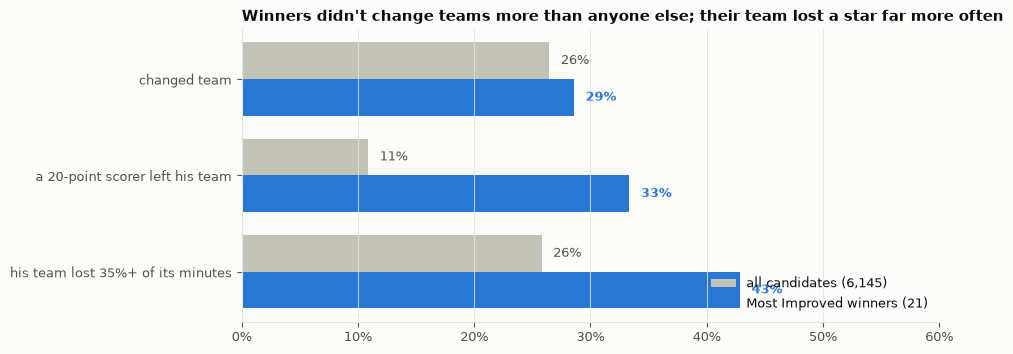

In [4]:
rows = ["changed team", "a 20-point scorer left his team", "his team lost 35%+ of its minutes"]
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(rows)); h = 0.38
ax.barh(y - h / 2, share.loc[rows, "all candidates"], h, color=MUTED, label=f"all candidates ({len(e):,})")
ax.barh(y + h / 2, share.loc[rows, "winners"], h, color=BLUE, label=f"Most Improved winners ({int(e['mip'].sum())})")
for yi, r in zip(y, rows):
    ax.text(share.loc[r, "all candidates"] + 0.01, yi - h / 2, f"{share.loc[r, 'all candidates']:.0%}", va="center", fontsize=9, color=INK2)
    ax.text(share.loc[r, "winners"] + 0.01, yi + h / 2, f"{share.loc[r, 'winners']:.0%}", va="center", fontsize=9, color=BLUE, fontweight="bold")
ax.set_yticks(y, rows); ax.invert_yaxis(); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xlim(0, 0.6)
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
ax.set_title("Winners didn't change teams more than anyone else; their team lost a star far more often", loc="left")
fig.savefig(FIG_DIR / "14_team_change_vs_winners.png", dpi=150, bbox_inches="tight")

In [5]:
e[e["mip"]][["season", "player_name", "changed_team", "star_left", "team_minutes_left", "playmaker_arrived", "star_arrived"]].sort_values("season").round(2).set_index("season")

,player_name,changed_team,star_left,team_minutes_left,playmaker_arrived,star_arrived
season,,,,,,
2005-06,Boris Diaw,True,False,0.41,False,False
2006-07,Monta Ellis,False,False,0.20,False,False
2007-08,Hedo Turkoglu,False,False,0.29,False,True
2008-09,Danny Granger,False,False,0.35,False,False
2009-10,Aaron Brooks,False,False,0.36,False,False
2010-11,Kevin Love,False,False,0.57,False,False
2011-12,Ryan Anderson,False,False,0.16,False,False
2012-13,Paul George,False,False,0.30,True,False
2013-14,Goran Dragic,False,False,0.62,False,False


## 14B — Does a team change, or a teammate change, lead to real improvement?

All candidates, not just award winners. Grouped by age because many movers are veterans being moved on.

In [6]:
def outcome(d):
    return pd.Series({"players": len(d), "jumped +3 points": d["jump3"].mean(), "points change": d["ppg_delta"].mean(), "game score change": d["game_score_delta"].mean()})
display(e.groupby([e["young"].map({True: "under 25", False: "25 and over"}), e["changed_team"].map({True: "changed team", False: "stayed"})]).apply(outcome).round(2))
stay = e[~e["changed_team"]]
events = pd.concat({f: stay.groupby(stay[f].map({True: "yes", False: "no"})).apply(outcome) for f in ["star_left", "open_role", "playmaker_arrived", "star_arrived"]})
events.index.names = ["event on his team (players who stayed)", ""]
events.round(2)

players  jumped +3 points  points change  \
young       changed_team                                             
25 and over changed team   1409.0              0.11          -0.79   
            stayed         2970.0              0.11          -0.28   
under 25    changed team    217.0              0.31           0.99   
            stayed         1549.0              0.29           1.42   

                          game score change  
young       changed_team                     
25 and over changed team              -0.56  
            stayed                    -0.19  
under 25    changed team               0.93  
            stayed                     1.23

players  jumped +3 points  \
event on his team (players who stayed)                                  
star_left                              no    4076.0              0.16   
                                       yes    443.0              0.28   
open_role                              no    3611.0              0.16   
                                       yes    908.0              0.22   
playmaker_arrived                      no    4101.0              0.18   
                                       yes    418.0              0.16   
star_arrived                           no    4167.0              0.17   
                                       yes    352.0              0.16   

                                            points change  game score change  
event on his team (players who stayed)                                        
star_left                              no            0.22               0.25  
                                       yes           1.10               0.76  
open_role                              no            0.24               0.25  
                                       yes           0.55               0.48  
playmaker_arrived                      no            0.33               0.32  
                                       yes           0.02               0.06  
star_arrived                           no            0.32               0.30  
                                       yes           0.10               0.20

## 14C — A playmaker arrives mid-season: what happens to his new teammates?

Your example: Trae Young joined Washington in March 2026. For every playmaker (6+ assists in 25+ minutes the season before) traded mid-season since 2005-06, each new teammate's games **before vs after** his arrival, same season. Teammates need 8+ games on each side and 15+ minutes a game.

In [7]:
g2 = g.assign(pts36=36 * g["pts"] / g["min"].where(g["min"] > 0), gs36=36 * g["game_score"] / g["min"].where(g["min"] > 0))
moved = summ[summ["first_team"] != summ["last_team"]].merge(prev[["player_id", "season_start", "apg_prev", "mpg_prev"]], on=["player_id", "season_start"])
pms = moved[(moved["apg_prev"] >= 6) & (moved["mpg_prev"] >= 25)]
rows = []
for _, pm in pms.iterrows():
    mine = g2[(g2["season_start"] == pm["season_start"]) & (g2["player_id"] == pm["player_id"]) & (g2["team_id"] == pm["last_team"])]
    arrive = mine["game_date"].min()
    mates = g2[(g2["season_start"] == pm["season_start"]) & (g2["team_id"] == pm["last_team"]) & (g2["player_id"] != pm["player_id"])]
    for pid, d in mates.groupby("player_id"):
        b, a = d[d["game_date"] < arrive], d[d["game_date"] >= arrive]
        if len(b) >= 8 and len(a) >= 8 and d["min"].mean() >= 15:
            rows.append({"season": pm["season_start"], "playmaker": pm["name"], "teammate": d["player_name"].iloc[-1],
                         "minutes": a["min"].mean() - b["min"].mean(), "points per 36": a["pts36"].mean() - b["pts36"].mean(),
                         "game score per 36": a["gs36"].mean() - b["gs36"].mean(),
                         "true shooting": a["pts"].sum() / (2 * a["tsa"].sum()) - b["pts"].sum() / (2 * b["tsa"].sum())})
pm_effect = pd.DataFrame(rows)
g2["second_half"] = g2.groupby("season_start")["game_date"].transform(lambda s: s >= s.quantile(0.5))
drift = g2[g2["min"] >= 15].groupby("second_half")[["pts36", "gs36"]].mean()
print(f"{len(pm_effect)} teammate stints from {pm_effect['playmaker'].nunique()} mid-season playmaker trades")
print(f"league-wide drift, second half minus first: points per 36 {drift.loc[True, 'pts36'] - drift.loc[False, 'pts36']:+.2f}, game score per 36 {drift.loc[True, 'gs36'] - drift.loc[False, 'gs36']:+.2f}")
pm_effect[["minutes", "points per 36", "game score per 36", "true shooting"]].agg(["mean", "median"]).round(3)

300 teammate stints from 34 mid-season playmaker trades
league-wide drift, second half minus first: points per 36 +0.19, game score per 36 +0.35


,minutes,points per 36,game score per 36,true shooting
mean,0.891,0.392,0.539,0.005
median,0.409,0.538,0.671,0.004


In [8]:
# Alex Sarr: before Trae Young, with Trae Young (2025-26 and 2026-27 so far)
trae = games[games["player_name"].str.contains("Trae Young") & (games["team_abbreviation"] == "WAS")]
sarr = games[games["player_name"].str.contains("Alex Sarr") & (games["season_start"] >= 2025)].copy()
sarr["period"] = np.where(sarr["game_id"].isin(trae["game_id"]), "with Trae Young on the floor that night",
                          np.where(sarr["game_date"] < trae["game_date"].min(), "2025-26 before Trae arrived", "after Trae arrived, Trae out"))
sarr.groupby("period").apply(lambda d: pd.Series({"games": len(d), "minutes": d["min"].mean(), "points": d["pts"].mean(), "rebounds": d["reb"].mean(),
                                                  "game score": d["game_score"].mean(), "true shooting": d["pts"].sum() / (2 * d["tsa"].sum())})).round(2)

,games,minutes,points,rebounds,game score,true shooting
period,,,,,,
2025-26 before Trae arrived,41.0,28.22,17.17,7.78,14.65,0.55
"after Trae arrived, Trae out",4.0,21.50,13.00,5.75,8.35,0.47
with Trae Young on the floor that night,8.0,23.38,10.00,4.75,9.27,0.55


## 14D — Do these help the model pick the winner?

The end-of-season model from notebook 10, rebuilt on the 21 seasons with game-log inputs only (the older seasons lack usage and start rate): changes in points, rebounds, assists, steals, blocks, minutes, game score and true shooting; relative change in points and game score; team win % change; age; second-year flag. Each season is predicted by a model that never saw it; *strict* = trained on earlier seasons only (13 seasons, 2013-14 on).

In [9]:
e["changed_team_f"], e["star_left_f"] = e["changed_team"].astype(float), e["star_left"].astype(float)
BASE = GAMELOG_DELTAS + GAMELOG_DEFENSE + RELATIVE + TEAM + AGE + SECOND_YEAR

def evaluate(d, feats, l2=3.0, first_strict=8):
    out = {}
    for scheme in ["leave-one-out", "strict"]:
        rk, ll = [], []
        for i, s in enumerate(sorted(d["season"].unique())):
            if scheme == "strict" and i < first_strict:
                continue
            te = d[d["season"] == s]
            train = d[d["season"] != s] if scheme == "leave-one-out" else d[d["season"] < s]
            p = ChoiceModel(feats, l2).fit(train).predict_proba(te)
            rk.append(int(p.rank(ascending=False, method="min")[te["mip"]].iloc[0])); ll.append(np.log(p[te["mip"]].iloc[0] * len(te)))
        rk = np.array(rk)
        out.update({f"{scheme}: winner #1": int((rk == 1).sum()), f"{scheme}: in top 3": int((rk <= 3).sum()), f"{scheme}: median rank": np.median(rk),
                    f"{scheme}: × blind guess": np.exp(np.mean(ll))})
    return out

end_of_season = pd.DataFrame({"box-score changes + team + age + second year": evaluate(e, BASE), "+ changed team": evaluate(e, BASE + ["changed_team_f"]),
                              "+ a star left his team": evaluate(e, BASE + ["star_left_f"]), "+ both": evaluate(e, BASE + ["changed_team_f", "star_left_f"])}).T
w = ChoiceModel(BASE + ["changed_team_f", "star_left_f"], 3.0).fit(e).coefficients()[["changed_team_f", "star_left_f"]]
print(f"weights (per SD): changed team {w['changed_team_f']:+.2f}, a star left {w['star_left_f']:+.2f}")
end_of_season.round(1)

weights (per SD): changed team +0.05, a star left +0.32


,leave-one-out: winner #1,leave-one-out: in top 3,leave-one-out: median rank,leave-one-out: × blind guess,strict: winner #1,strict: in top 3,strict: median rank,strict: × blind guess
box-score changes + team + age + second year,9.0,11.0,2.0,24.8,6.0,8.0,2.0,28.8
+ changed team,8.0,11.0,2.0,23.9,5.0,7.0,3.0,26.3
+ a star left his team,8.0,11.0,2.0,25.9,5.0,8.0,2.0,28.9
+ both,8.0,11.0,2.0,25.0,5.0,7.0,2.0,26.4


In [10]:
# preseason model (notebook 11, 14 seasons): "a star left" known before the season = the star is seen with another team in preseason
from unicorn.labels import MIP_WINNERS
from unicorn.preseason import USED, add_pool_flags, add_turning_point, load_preseason, preseason_frame
reg = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_games.parquet")
pre = load_preseason(regular=reg)
F = add_turning_point(add_pool_flags(preseason_frame(pre, reg, ps), MIP_WINNERS))
end = reg.sort_values("game_date").groupby(["player_id", "season_start"]).agg(team=("team_id", "last"), ppg=("pts", "mean")).reset_index()
pre_team = pre.sort_values("game_date").groupby(["player_id", "season_start"])["team_id"].last()
end["pre_team_next"] = [pre_team.get((p, s + 1)) for p, s in zip(end["player_id"], end["season_start"])]
left = end[(end["ppg"] >= 20) & end["pre_team_next"].notna() & (end["pre_team_next"] != end["team"])]
left_set = set(zip(left["team"], left["season_start"] + 1))
F["star_left_pre"] = [float((t, s) in left_set) for t, s in zip(F["team_id"], F["season_start"])]
FH = F[F["season"] != "2026-27"].reset_index(drop=True)
print(f"winners whose team had lost a 20-point scorer by preseason: {int(FH.loc[FH['mip'], 'star_left_pre'].sum())} of {int(FH['mip'].sum())}; all candidates: {FH['star_left_pre'].mean():.0%}")
pd.DataFrame({"preseason model (used)": evaluate(FH, USED, first_strict=5), "+ a star left": evaluate(FH, USED + ["star_left_pre"], first_strict=5)}).T.round(1)

winners whose team had lost a 20-point scorer by preseason: 6 of 14; all candidates: 10%


,leave-one-out: winner #1,leave-one-out: in top 3,leave-one-out: median rank,leave-one-out: × blind guess,strict: winner #1,strict: in top 3,strict: median rank,strict: × blind guess
preseason model (used),1.0,3.0,11.5,5.6,0.0,1.0,14.0,3.3
+ a star left,1.0,2.0,8.0,6.8,0.0,2.0,15.0,4.6


### 14 findings

**1. Changing team, on its own, does not make a Most Improved Player.**
- 29% of winners had changed teams since their baseline season, against 27% of all candidates: no difference.
- Voters, if anything, look past movers: only 13% of the real voting top 7 had changed teams.
- Movers improve no more than players who stay. Under 25: 31% vs 29% jumped +3 points. 25 and over: 11% vs 11%, and older movers' scoring falls further (−0.8 vs −0.3 points), because many are veterans being moved on.
- As a model input it adds nothing (weight +0.05; the fit gets slightly worse).

**2. What matters is the role that opens up: a star leaving the player's team.**
- **7 of 21 winners (33%) had a 20-point scorer leave their team, against 11% of all candidates: three times the rate.** Six of the last nine winners fit this: CJ McCollum (LaMarcus Aldridge left Portland), Victor Oladipo (Paul George left Indiana), Pascal Siakam (DeMar DeRozan left Toronto), Brandon Ingram (Anthony Davis left New Orleans), Lauri Markkanen (Donovan Mitchell left Utah), Tyrese Maxey (James Harden left Philadelphia). Dyson Daniels' Atlanta had lost Dejounte Murray too.
- **For all players who stayed, not just winners:** when a 20-point scorer left, 28% jumped +3 points, against 16% when nobody did (+1.1 vs +0.2 points on average).
- **A wider version, "the team lost 35%+ of last season's minutes":** 43% of winners against 26% of candidates, and a weaker lift for everyone (22% vs 16% jumped).
- **This is what drives your "new team" intuition:** Oladipo, Ingram, Markkanen and Daniels changed teams *into* a team that had just lost its star. The move mattered because of the role waiting there.

**3. New teammates: no lift on average.**
- **A playmaker or a 20-point scorer arriving in the summer:** the players already there improved slightly *less* than usual (+0.0 and +0.1 points, against +0.3). The ball gets shared.
- **A playmaker traded in mid-season** (34 trades, 300 teammates): teammates' game score per 36 rose by 0.54, but every player rises about 0.35 from the first half of a season to the second. That leaves about +0.2 per 36: barely anything. Shooting efficiency was unchanged (+0.5 points of true shooting).
- **Alex Sarr with Trae Young:** in 8 games with Trae on the floor, 10.0 points on 55% true shooting in 23 minutes, against 17.2 points on 55% in 28 minutes before Trae arrived. He scores less, with the same efficiency. If he looks better, it isn't in the box score yet, and 8 games is far too few to say.

**4. Does "a star left" help the models?**
- **End of season (21 seasons):** barely. Weight +0.32; the overall fit improves slightly in the leave-one-out test (24.8× → 25.9× a blind guess), is unchanged in the strict test, and costs one #1. Once the season is over, the box-score jump already shows the bigger role.
- **Preseason (14 seasons): yes, clearly.** 6 of 14 winners' teams had lost a 20-point scorer by preseason, against 10% of candidates. Adding it improves the fit in both tests (leave-one-out 5.6× → 6.8×, median winner rank 11.5 → 8; strict 3.3× → 4.6×). Before the season, it is one of the few signs of the role that is about to open up.

**Decision for you:** add "a 20-point scorer left his team" to the preseason model (notebook 11) and the pre-season snapshots in notebook 12? It passes the test that preseason minutes and opportunity failed.